In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, classification_report, accuracy_score)
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

# Импортируем встроенный датасет пингвинов и используем его для классификации

In [2]:
df = sns.load_dataset("penguins")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


Проверим датасет на наличие пропущенных значений

In [3]:
df.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

**Мы видим, что в датасете наблюдаются пропуски.**
Позднее используем тогда еще и класс `SimpleImputer` из `sklearn.impute`.

Но для начала разделим данные на обучающую и тестовую выборки

In [4]:
X = df.drop(columns=["species"])
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

### Мы будем использовать преобразования категориальных и числовых признаков раздельно.
Для этого используем пайплайны и `ColumnTransformer`.

In [5]:
categories = ['island', 'sex']
nums = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy="most_frequent")),
    ('encoder', OneHotEncoder(sparse_output=False)),
])

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy="median")),
    ('scaler', StandardScaler()),
])

transformer = ColumnTransformer([
    ('cat_pipe', cat_pipe, categories),
    ("num_pipe", num_pipe, nums),
])

**Преобразуем наши данные**

In [6]:
X_train_transformed = transformer.fit_transform(X_train)
X_test_transformed = transformer.transform(X_test)

### Для многоклассовой классификации будем использовать метод Один-против-Всех (`OneVsRestClassifier`)

In [7]:
model = OneVsRestClassifier(
    LogisticRegression()
)
model.fit(X_train_transformed, y_train)

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",LogisticRegression()
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
Name,Type,Value
"classes_ classes_: array, shape = [`n_classes`]Class labels.","ndarray[<U9](3,)","['Adelie','Chinstrap','Gentoo']"
estimators_ estimators_: list of `n_classes` estimatorsEstimators used for predictions.,list,"[LogisticRegression(), LogisticRegression(), LogisticRegression()]"
label_binarizer_ label_binarizer_: LabelBinarizer objectObject used to transform multiclass labels to binary labels andvice-versa.,LabelBinarizer,LabelBinarize...e_output=True)
multilabel_ multilabel_: booleanWhether a OneVsRestClassifier is a multilabel classifier.,bool,False
n_classes_ n_classes_: intNumber of classes.,int,3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,9
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'


In [8]:
y_pred = model.predict(X_test_transformed)

## Проверим нашу модель по основным метрикам классификации по очереди

1. Для начала посмотрим Accuracy, то есть долю правильных предсказаний

In [9]:
print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")

Accuracy: 98.55%


$Accuracy=98.55\%$ — точность очень высокая

Далее посмотрим матирицу ошибок (`confusion_matrix`)

In [10]:
print(f"Confusion Matrix: \n{confusion_matrix(y_test, y_pred)}")

Confusion Matrix: 
[[32  0  0]
 [ 1 15  0]
 [ 0  0 21]]


Мы видим, что наша модель 1 класс определила неправильно:
1. первый класс — все правильно
2. второй — один объект ошибочно отнесли к первому классу
3. третий — все правильно

Далее мы посмотрим на основные метрики через `classfification_report`, а именно:
1. precision — из всех положительно определенных объектов, сколько было правильных
2. recall — из всех действительно положительных объектов, сколько модель смогла обнаружить
3. f1-score — гармоническое среднее precision и recall
4. и количество объектов в принципе в каждом классе

In [11]:
print(f"Classification Report: \n{classification_report(y_test, y_pred)}")

Classification Report: 
              precision    recall  f1-score   support

      Adelie       0.97      1.00      0.98        32
   Chinstrap       1.00      0.94      0.97        16
      Gentoo       1.00      1.00      1.00        21

    accuracy                           0.99        69
   macro avg       0.99      0.98      0.98        69
weighted avg       0.99      0.99      0.99        69



Распишем результаты подробно для каждого класса:
1. **Adelie**
- precision = 0.97 — то есть из всех объектов, что он отнес к Adelie, 97% были правильными, то есть есть 3% (в нашем случае это 1 пингвин) $FP$
- recall = 1.00 — то есть из всех пингвинов, которые были Adelie, модель все 32 объекта _правильно_ классифицировала. То есть для этого класса нет $FN$
2. **Chinstrap**
- precision = 1.00 — всех пингвинов, которые действительно Chinstrap модель правильно отнесла к этому классу. То есть для этого класса нет ни одного $FP$
- recall = 0.94 — то есть, из всех действительно пингвинов CHinstrap модель отнесла к этому классу 94%, то есть для этого класса есть 6% (в нашем случае это 1 пингвин), которые $FN$
3. **Gentoo**
- precision = 1.00 — из всех пингвинов, которые модель отнесла к Gentoo, все были правильными, то есть $FP$ нет
- recall = 1.00 — из всех действительно пингвинов Gentoo модель отнесла всех к нужному классу

# Далее построим ROC-кривую.
Но для этого нам нужны не предсказанные классы, а вероятности принадлежности объекта к каждрому классу. Поэтому сначала найдем вероятности `probability` через `predict_proba`.

In [12]:
y_proba = model.predict_proba(X_test_transformed)
y_proba.shape

(69, 3)

Text(0.5, 1.0, 'ROC-Curve')

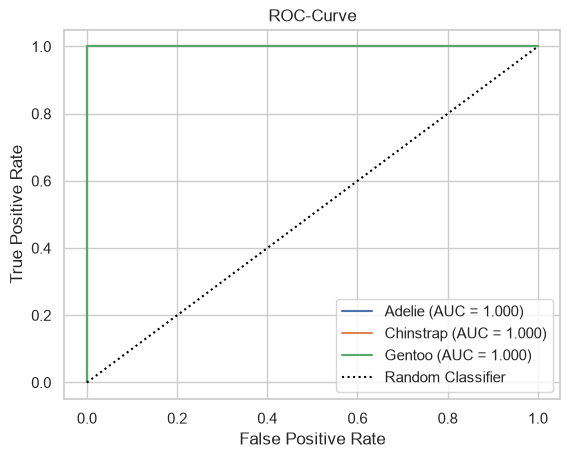

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize

sns.set_theme(style="whitegrid", font="Arial")

y_test_bin = label_binarize(
    y_test,
    classes=model.classes_
)
y_proba = model.predict_proba(X_test_transformed)

for i, class_name in enumerate(model.classes_):
    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i],
        y_proba[:, i],
    )

    auc = roc_auc_score(
        y_test_bin[:, i],
        y_proba[:, i]
    )

    sns.lineplot(
        x=fpr,
        y=tpr,
        estimator=None,
        sort=False,
        label=f"{class_name} (AUC = {auc:.3f})"
    )

# Диагональ случайного классификатора
sns.lineplot(
    x=[0, 1],
    y=[0, 1],
    color="black",
    linestyle=":",
    label="Random Classifier",
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-Curve")

In [14]:
auc = roc_auc_score(
    y_test,
    y_proba,
    multi_class="ovr",
    average="macro",
)
print(auc)

1.0


***
# Регрессия. Предсказание массы пингвинов

In [15]:
X = df.drop(columns=["body_mass_g"])
y = df["body_mass_g"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

In [29]:
categories = ['island', 'sex', 'species']
nums = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm",]

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy="most_frequent")),
    ('encoder', OneHotEncoder(sparse_output=False)),
])

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy="median")),
    ('scaler', StandardScaler()),
])

transformer = ColumnTransformer([
    ('cat_pipe', cat_pipe, categories),
    ("num_pipe", num_pipe, nums),
])

X_train_transformed = transformer.fit_transform(X_train)
X_test_transformed = transformer.transform(X_test)
y_train_transformed = y_train.fillna(y_train.mean())
y_test_transformed = y_test.fillna(y_test.mean())

In [38]:
from sklearn.linear_model import (HuberRegressor, LinearRegression, Ridge, Lasso)

huber = HuberRegressor(
    epsilon=1.35,
    max_iter=100,
    alpha=0.0001
)

ridge = Ridge(
    alpha=1.0,
)

line = LinearRegression()

lasso = Lasso(alpha=1.0, fit_intercept=True)

In [39]:
huber.fit(X_train_transformed, y_train_transformed)
ridge.fit(X_train_transformed, y_train_transformed)
line.fit(X_train_transformed, y_train_transformed)
lasso.fit(X_train_transformed, y_train_transformed)

y_pred_h = huber.predict(X_test_transformed)
y_pred_r = ridge.predict(X_test_transformed)
y_pred_lin = line.predict(X_test_transformed)
y_pred_las = lasso.predict(X_test_transformed)

In [42]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

predictions = {
    'HuberRegressor': y_pred_h,
    'Ridge': y_pred_r,
    'LinearRegression': y_pred_lin,
    'Lasso': y_pred_las
}

results = []
r2_list = []

for name, y_pred in predictions.items():
    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test_transformed, y_pred),
        'MSE': mean_squared_error(y_test_transformed, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test_transformed, y_pred)),
        'R2': r2_score(y_test_transformed, y_pred)
    })

    r2_list.append(r2_score(y_test_transformed, y_pred))

results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))

           Model     MAE        MSE    RMSE    R2
  HuberRegressor 253.138 102846.597 320.697 0.834
           Ridge 254.903 103286.282 321.382 0.833
LinearRegression 254.282 103471.825 321.670 0.833
           Lasso 254.813 103564.944 321.815 0.833


In [43]:
r2_list

[0.8339996999652237,
 0.8332900223333535,
 0.8329905464873129,
 0.8328402462139788]

<Axes: >

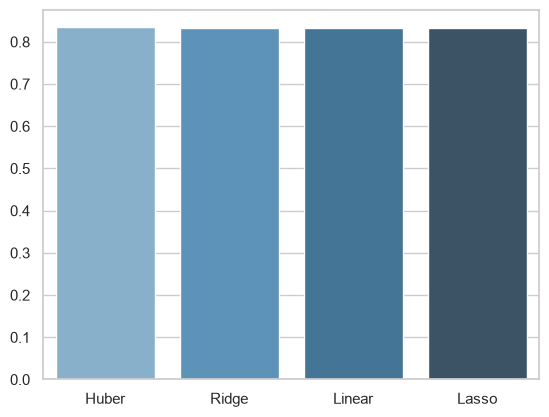

In [50]:
sns.barplot(x=models, y=r2_list, hue=models, palette="Blues_d")

In [47]:
type(models)

list

In [48]:
models

['Huber', 'Ridge', 'Linear', 'Lasso']